In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.inspection import DecisionBoundaryDisplay


In [2]:
# load the pharmacy sales dataset
df = pd.read_csv("global_pharmacy_sales_2020_2025_daily_dataset.csv")

# display the first five rows
display(df.head())

# check the dataset size and column names
print("dataset shape:", df.shape)
print("columns:", df.columns.tolist())


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


dataset shape: (177990, 14)
columns: ['date', 'year', 'month', 'day', 'region', 'country', 'category', 'medicine', 'age_group', 'units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']


In [3]:
# create high and low demand classes using median sales
median_sales = df["units_sold"].median()

df["demand_class"] = np.where(
    df["units_sold"] >= median_sales,
    "high demand",
    "low demand"
)

# check the class distribution
print(df["demand_class"].value_counts())


demand_class
high demand    89217
low demand     88773
Name: count, dtype: int64


In [4]:
# select numerical features for knn classification
features = [
    "unit_price",
    "stock_level",
    "expiry_days_remaining",
    "month",
    "covid_flag"
]

X = df[features]
y = df["demand_class"]

# check for missing values
print(X.isnull().sum())


unit_price               0
stock_level              0
expiry_days_remaining    0
month                    0
covid_flag               0
dtype: int64


In [5]:
# use a sample to make grid search faster
data = df.sample(n=min(12000, len(df)), random_state=42)

X = data[features]
y = data["demand_class"]

# split the data while maintaining class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("training records:", len(X_train))
print("testing records:", len(X_test))


training records: 9600
testing records: 2400


In [6]:
# scale features before calculating distances
# use a pipeline to prevent data leakage during cross-validation
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# define the k values and voting methods to test
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "knn__weights": ["uniform", "distance"]
}


In [7]:
# test different k values using three-fold cross-validation
grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1
)

# train and compare all parameter combinations
grid_search.fit(X_train, y_train)

# display the best parameters
print("best parameters:", grid_search.best_params_)
print("best cross-validation f1:", grid_search.best_score_)

best_model = grid_search.best_estimator_


best parameters: {'knn__n_neighbors': 21, 'knn__weights': 'uniform'}
best cross-validation f1: 0.8389073849584436


In [8]:

# predict the demand class for test records
y_pred = best_model.predict(X_test)

# calculate test accuracy
accuracy = accuracy_score(y_test, y_pred)
print("test accuracy:", round(accuracy * 100, 2), "%")

# display precision, recall, and f1-score
print(classification_report(y_test, y_pred))


test accuracy: 84.42 %
              precision    recall  f1-score   support

 high demand       0.85      0.83      0.84      1204
  low demand       0.83      0.86      0.85      1196

    accuracy                           0.84      2400
   macro avg       0.84      0.84      0.84      2400
weighted avg       0.84      0.84      0.84      2400



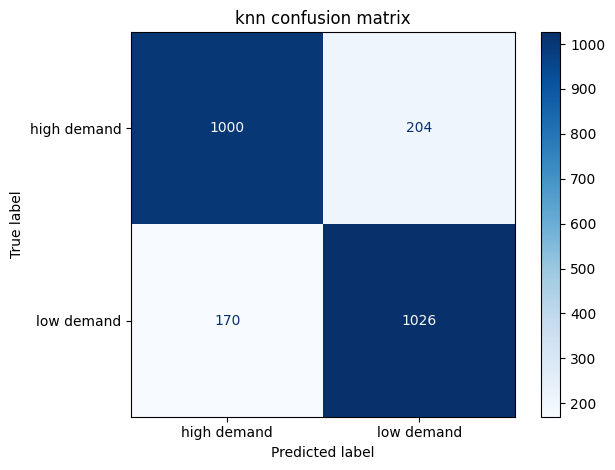

In [9]:

# compare actual and predicted classes
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("knn confusion matrix")
plt.tight_layout()
plt.show()


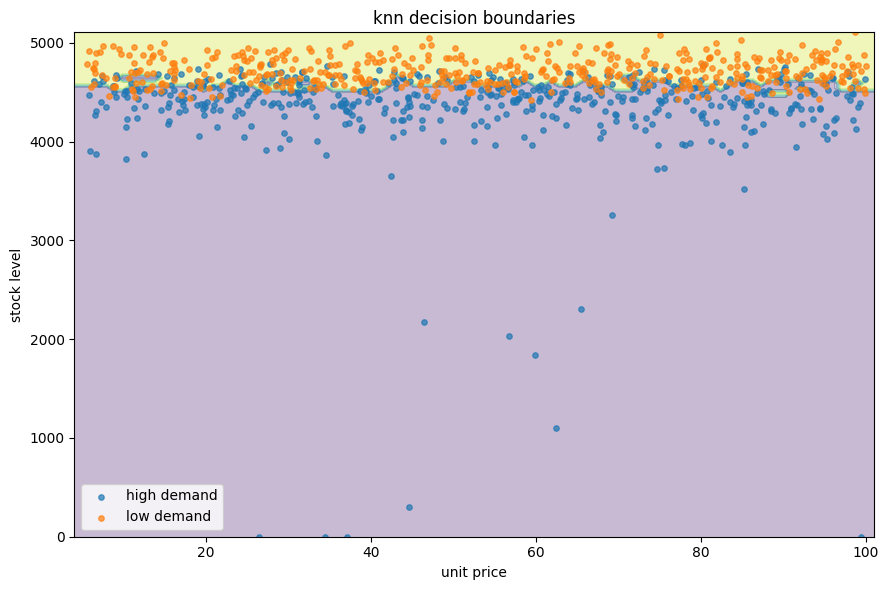

In [10]:

# select two features for a two-dimensional visualization
X_2d = data[["unit_price", "stock_level"]]
y_2d = data["demand_class"]

# split the two-feature dataset
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d, y_2d,
    test_size=0.20,
    random_state=42,
    stratify=y_2d
)

# create a scaled knn model for visualization
boundary_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(
        n_neighbors=grid_search.best_params_["knn__n_neighbors"],
        weights=grid_search.best_params_["knn__weights"]
    ))
])

# train the two-feature model
boundary_model.fit(X2_train, y2_train)

# draw the decision boundaries
fig, ax = plt.subplots(figsize=(9, 6))

DecisionBoundaryDisplay.from_estimator(
    boundary_model,
    X2_train,
    response_method="predict",
    alpha=0.3,
    grid_resolution=100,
    ax=ax
)

# display a sample of training points
sample_points = X2_train.sample(
    n=min(1000, len(X2_train)),
    random_state=42
)

sample_labels = y2_train.loc[sample_points.index]

for label in y2_train.unique():
    mask = sample_labels == label
    ax.scatter(
        sample_points.loc[mask, "unit_price"],
        sample_points.loc[mask, "stock_level"],
        label=label,
        s=15,
        alpha=0.7
    )

ax.set_xlabel("unit price")
ax.set_ylabel("stock level")
ax.set_title("knn decision boundaries")
ax.legend()
plt.tight_layout()
plt.show()


In [11]:

# summarize the model results
print("knn model development completed")
print("optimal parameters:", grid_search.best_params_)
print("cross-validation f1-score:", round(grid_search.best_score_, 4))
print("test accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("the model was tuned using grid search and cross-validation.")
print("test metrics and decision boundaries were used for evaluation.")


knn model development completed
optimal parameters: {'knn__n_neighbors': 21, 'knn__weights': 'uniform'}
cross-validation f1-score: 0.8389
test accuracy: 0.8442
the model was tuned using grid search and cross-validation.
test metrics and decision boundaries were used for evaluation.
